# Experimental versus diffusion morphometric comparison

Images are paired by filename stem (for example, `196_1.TIF` with `196_1.png`). The metrics are final-skeleton tip count, total geodesic skeleton length, terminal width measured 5 pixels inward, and segmented colony area.

In [31]:
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.ndimage import distance_transform_edt

from cldm.config import EXP_FOLDER_TEST, FPATH, MAIN_FOLDER
from cldm.preprocess import (
    preprocess_experimental_backgroundblack,
    preprocess_experimental_backgroundblack_blackandwhite,
    preprocess_experimental_backgroundblack_blackandwhite_nocropping,
)
from cldm.morpho_features import (
    SkeletonConfig, endpoint_pixel_map, skeletonize_colony,
    summarize_skeleton,
)
from cldm.display import create_skeleton_overlay

fm.fontManager.addfont(str(FPATH))
ARIAL_FONT_NAME = fm.FontProperties(fname=str(FPATH)).get_name()
plt.rcParams['font.family'] = ARIAL_FONT_NAME

In [30]:
# ======================== TUNABLE PARAMETERS ========================
SKELETON_CONFIG = SkeletonConfig(
    mask_smooth_sigma=1.25,
    mask_smooth_threshold=0.50,
    mask_min_object_px=64,
    mask_closing_radius_px=0,
    spur_factor=1.0,
    spur_min_px=2.0,
    radius_cap_px=8.0,
    max_prune_fraction=0.02,
    min_branches_for_pruning=5,
    blob_radius_factor=1.5,
    blob_min_radius_px=6.0,
    blob_min_core_area_px=50,
    blob_core_expansion_px=5,
    blob_interface_tolerance_px=4,
    blob_attachment_cluster_radius_px=2,
    blob_max_attachments=24,
    blob_min_attachments_for_hub=2,
    blob_path_cost_power=1.5,
    strand_radius_quantile=0.85,
)

TERMINAL_INSET_PX = 5.0
TERMINAL_TANGENT_DISTANCE_PX = 6.0
SAMPLE_COUNT = 10
RANDOM_SEED = 42
PIXEL_SIZE = None       # physical units per pixel, when calibrated
PHYSICAL_UNIT = 'mm'
SAVE_COMPARISON_CSV = None  # e.g. 'exp_diffusion_metrics.csv'
COMPARISON_LEGEND_FONTSIZE = 28
# ===================================================================

In [17]:
def path_distance(coordinates):
    """Cumulative distance along an 8-connected skeleton path."""
    steps = np.diff(coordinates.astype(float), axis=0)
    return np.r_[0.0, np.cumsum(np.linalg.norm(steps, axis=1))]


def terminal_paths(skeleton_result):
    """Return one path starting at each final-skeleton endpoint."""
    skeleton = skeleton_result['final']
    endpoint_map = endpoint_pixel_map(skeleton)
    skan_skeleton, branch_table = summarize_skeleton(skeleton)
    paths = []

    for branch_index in range(len(branch_table)):
        coordinates = skan_skeleton.path_coordinates(branch_index).astype(int)
        if endpoint_map[tuple(coordinates[0])]:
            paths.append(coordinates)
        if endpoint_map[tuple(coordinates[-1])]:
            paths.append(coordinates[::-1])

    return paths


def terminal_widths(skeleton_result):
    """Measure terminal widths 5 pixels inward; skip shorter paths."""
    distance_map = distance_transform_edt(skeleton_result['mask'])
    records = []

    for tip_index, coordinates in enumerate(terminal_paths(skeleton_result)):
        inward_distance = path_distance(coordinates)
        if inward_distance[-1] < TERMINAL_INSET_PX:
            continue

        measurement_index = np.searchsorted(inward_distance, TERMINAL_INSET_PX)
        measurement_index = min(measurement_index, len(coordinates) - 1)
        tangent_index = np.searchsorted(
            inward_distance, TERMINAL_TANGENT_DISTANCE_PX
        )
        tangent_index = min(tangent_index, len(coordinates) - 1)
        tip = coordinates[0].astype(float)
        measurement = coordinates[measurement_index].astype(float)
        tangent_point = coordinates[tangent_index].astype(float)
        width_px = 2 * distance_map[tuple(measurement.astype(int))]
        radius_px = width_px / 2

        # Diameter perpendicular to the local terminal direction.
        tangent = tangent_point - tip
        tangent /= np.linalg.norm(tangent)
        perpendicular = np.array([-tangent[1], tangent[0]])
        diameter_start = measurement - radius_px * perpendicular
        diameter_end = measurement + radius_px * perpendicular

        records.append({
            'tip_index': tip_index,
            'tip_y': int(tip[0]),
            'tip_x': int(tip[1]),
            'measurement_y': int(measurement[0]),
            'measurement_x': int(measurement[1]),
            'width_px': float(width_px),
            'diameter_start_y': float(diameter_start[0]),
            'diameter_start_x': float(diameter_start[1]),
            'diameter_end_y': float(diameter_end[0]),
            'diameter_end_x': float(diameter_end[1]),
        })

    return pd.DataFrame(records)


def image_metrics(binary_mask):
    """Calculate all four comparison metrics from one binary mask."""
    binary_mask = np.asarray(binary_mask, dtype=bool)
    skeleton_result = skeletonize_colony(binary_mask, config=SKELETON_CONFIG)
    _, branch_table = summarize_skeleton(skeleton_result['final'])
    widths = terminal_widths(skeleton_result)

    metrics = {
        'branch_tip_count': int(endpoint_pixel_map(skeleton_result['final']).sum()),
        'total_skeleton_length_px': float(branch_table['branch_distance'].sum()),
        'valid_width_count': len(widths),
        'mean_terminal_width_px': widths['width_px'].mean(),
        'sd_terminal_width_px': widths['width_px'].std(ddof=1),
        'median_terminal_width_px': widths['width_px'].median(),
        'colony_area_px': int(binary_mask.sum()),
        'colony_area_fraction': float(binary_mask.mean()),
    }

    if PIXEL_SIZE is not None:
        metrics[f'total_skeleton_length_{PHYSICAL_UNIT}'] = (
            metrics['total_skeleton_length_px'] * PIXEL_SIZE
        )
        metrics[f'mean_terminal_width_{PHYSICAL_UNIT}'] = (
            metrics['mean_terminal_width_px'] * PIXEL_SIZE
        )
        metrics[f'colony_area_{PHYSICAL_UNIT}2'] = (
            metrics['colony_area_px'] * PIXEL_SIZE**2
        )

    return metrics, skeleton_result, widths


def load_experimental(stem):
    path = os.path.join(EXP_FOLDER_TEST, stem + '.TIF')
    image = preprocess_experimental_backgroundblack(path)
    mask = preprocess_experimental_backgroundblack_blackandwhite(path)
    return image, mask


def load_diffusion(stem):
    path = os.path.join(MAIN_FOLDER, stem + '.png')
    image_bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    mask = preprocess_experimental_backgroundblack_blackandwhite_nocropping(path)
    return image, mask


def plot_metric_overlay(ax, image, skeleton_result, widths, title):
    overlay = create_skeleton_overlay(image, skeleton_result['final'])
    tips_y, tips_x = np.where(endpoint_pixel_map(skeleton_result['final']))
    ax.imshow(overlay)
    ax.scatter(tips_x, tips_y, s=20, c='cyan', edgecolors='black', linewidths=0.3)
    ax.scatter(
        widths['measurement_x'], widths['measurement_y'],
        s=16, c='yellow', edgecolors='black', linewidths=0.3,
    )
    ax.set_title(title, fontsize=9)
    ax.axis('off')

In [18]:
experimental_by_stem = {
    Path(filename).stem: filename
    for filename in os.listdir(EXP_FOLDER_TEST)
    if filename.lower().endswith(('.tif', '.tiff'))
}
diffusion_by_stem = {
    Path(filename).stem: filename
    for filename in os.listdir(MAIN_FOLDER)
    if filename.lower().endswith('.png')
}

paired_stems = sorted(
    experimental_by_stem.keys() & diffusion_by_stem.keys(),
    key=lambda stem: tuple(int(value) for value in stem.split('_')),
)
print(f'{len(paired_stems)} matched experiment–diffusion image pairs')

96 matched experiment–diffusion image pairs


## Complete paired dataframe

This cell processes every matched pair. It keeps the experimental and diffusion measurements side by side and adds signed diffusion-minus-experiment differences.

In [6]:
comparison_records = []

for image_number, stem in enumerate(paired_stems, start=1):
    _, experimental_mask = load_experimental(stem)
    _, diffusion_mask = load_diffusion(stem)
    exp_metrics, _, _ = image_metrics(experimental_mask)
    diff_metrics, _, _ = image_metrics(diffusion_mask)

    record = {
        'image_id': stem,
        **{f'exp_{key}': value for key, value in exp_metrics.items()},
        **{f'diffusion_{key}': value for key, value in diff_metrics.items()},
    }

    for metric in (
        'branch_tip_count',
        'total_skeleton_length_px',
        'mean_terminal_width_px',
        'colony_area_px',
        'colony_area_fraction',
    ):
        record[f'delta_{metric}'] = diff_metrics[metric] - exp_metrics[metric]

    comparison_records.append(record)

    if image_number % 10 == 0 or image_number == len(paired_stems):
        print(f'Processed {image_number}/{len(paired_stems)} pairs')

comparison_df = pd.DataFrame(comparison_records).set_index('image_id')
display(comparison_df)

if SAVE_COMPARISON_CSV is not None:
    comparison_df.to_csv(SAVE_COMPARISON_CSV)
    print(f'Saved {SAVE_COMPARISON_CSV}')

Processed 10/96 pairs
Processed 20/96 pairs
Processed 30/96 pairs
Processed 40/96 pairs
Processed 50/96 pairs
Processed 60/96 pairs
Processed 70/96 pairs
Processed 80/96 pairs
Processed 90/96 pairs
Processed 96/96 pairs


,exp_branch_tip_count,exp_total_skeleton_length_px,exp_valid_width_count,exp_mean_terminal_width_px,exp_sd_terminal_width_px,exp_median_terminal_width_px,exp_colony_area_px,exp_colony_area_fraction,diffusion_branch_tip_count,diffusion_total_skeleton_length_px,...,diffusion_mean_terminal_width_px,diffusion_sd_terminal_width_px,diffusion_median_terminal_width_px,diffusion_colony_area_px,diffusion_colony_area_fraction,delta_branch_tip_count,delta_total_skeleton_length_px,delta_mean_terminal_width_px,delta_colony_area_px,delta_colony_area_fraction
image_id,,,,,,,,,,,,,,,,,,,,,
196_1,23,1531.989032,23,11.238195,1.944317,10.770330,17812,0.271790,23,1989.192134,...,11.612948,4.079923,10.000000,24686,0.376678,0,457.203102,0.374753,6874,0.104889
196_2,23,1530.834703,23,13.407896,2.838465,12.165525,20112,0.306885,23,1993.192134,...,11.725441,4.166003,10.198039,24572,0.374939,0,462.357431,-1.682455,4460,0.068054
197_1,28,2344.601297,28,13.874867,4.395562,13.416408,34622,0.528290,33,2287.258152,...,10.606478,2.781563,10.000000,31248,0.476807,5,-57.343146,-3.268389,-3374,-0.051483
197_2,23,2053.736290,23,13.813630,4.216976,13.416408,34375,0.524521,25,2244.802307,...,9.349756,2.437141,8.944272,30439,0.464462,2,191.066017,-4.463874,-3936,-0.060059
198_1,14,758.293506,14,13.550616,4.088738,13.395623,10196,0.155579,27,1920.878426,...,10.141111,3.784730,10.000000,25591,0.390488,13,1162.584920,-3.409505,15395,0.234909
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249_2,22,1264.567676,22,12.435349,3.280287,12.324555,16015,0.244370,25,2240.128209,...,9.912460,3.133013,8.944272,25731,0.392624,3,975.560533,-2.522889,9716,0.148254
250_1,33,1635.788022,33,12.591159,2.959466,12.649111,22027,0.336105,36,2661.029796,...,11.465835,3.182229,11.042019,32889,0.501846,3,1025.241774,-1.125323,10862,0.165741
250_2,30,1594.959595,30,13.617404,2.552815,13.416408,22305,0.340347,28,2180.412480,...,11.935735,3.878112,11.042019,29016,0.442749,-2,585.452886,-1.681669,6711,0.102402


## Simulation measurements and three-way comparisons

Simulations use the same crop and 256 × 256 grid as the experimental preprocessing.
The threshold below segments white simulated colonies from the black background.
All four metrics then use the existing image_metrics function and skeleton settings.
Area is measured on the input binary mask, as for the other two datasets.
Both replicates are retained as individual rows; duplicated simulation replicates
should not be treated as independent samples in later statistical tests.


In [19]:
from cldm.config import SIM_FOLDER_TEST
from cldm.preprocess import preprocess_simulation

# ================= SIMULATION PARAMETERS =================
SIMULATION_THRESHOLD = 110
SIMULATION_BLUR_KERNEL = 5  # set to 1 to disable this preprocessing blur
# =========================================================

simulation_by_stem = {
    Path(filename).stem: filename
    for filename in os.listdir(SIM_FOLDER_TEST)
    if filename.lower().endswith(('.tif', '.tiff'))
}
three_way_stems = [stem for stem in paired_stems if stem in simulation_by_stem]
print(f'{len(three_way_stems)} matched experiment–diffusion–simulation images')


def load_simulation(stem):
    path = os.path.join(SIM_FOLDER_TEST, simulation_by_stem[stem])
    grayscale = preprocess_simulation(path)
    blurred = cv2.GaussianBlur(
        grayscale, (SIMULATION_BLUR_KERNEL, SIMULATION_BLUR_KERNEL), 0
    )
    mask = blurred > SIMULATION_THRESHOLD
    display_image = mask.astype(np.uint8) * 255
    return display_image, mask


96 matched experiment–diffusion–simulation images


In [20]:
# Calculate every matched simulation once and keep its terminal measurements.
simulation_records = []
simulation_width_tables = []
simulation_results = {}

for image_number, stem in enumerate(three_way_stems, start=1):
    image, mask = load_simulation(stem)
    metrics, skeleton_result, widths = image_metrics(mask)

    simulation_records.append({'image_id': stem, **metrics})
    simulation_results[stem] = {
        'image': image, 'skeleton': skeleton_result,
        'widths': widths, 'metrics': metrics,
    }
    simulation_width_tables.append(widths.assign(image_id=stem))

    if image_number % 10 == 0 or image_number == len(three_way_stems):
        print(f'Processed {image_number}/{len(three_way_stems)} simulations')

simulation_df = pd.DataFrame(simulation_records).set_index('image_id')
simulation_terminal_widths = pd.concat(simulation_width_tables, ignore_index=True)
display(simulation_df)


Processed 10/96 simulations
Processed 20/96 simulations
Processed 30/96 simulations
Processed 40/96 simulations
Processed 50/96 simulations
Processed 60/96 simulations
Processed 70/96 simulations
Processed 80/96 simulations
Processed 90/96 simulations
Processed 96/96 simulations


,branch_tip_count,total_skeleton_length_px,valid_width_count,mean_terminal_width_px,sd_terminal_width_px,median_terminal_width_px,colony_area_px,colony_area_fraction
image_id,,,,,,,,
196_1,19,977.116882,19,13.328280,1.264523,12.806248,12791,0.195175
196_2,19,977.116882,19,13.328280,1.264523,12.806248,12791,0.195175
197_1,27,1120.945310,27,14.508496,1.927492,14.000000,17607,0.268661
197_2,27,1120.945310,27,14.508496,1.927492,14.000000,17607,0.268661
198_1,10,552.842712,10,13.117233,0.613016,12.806248,7290,0.111237
...,...,...,...,...,...,...,...,...
249_2,19,1011.933116,19,13.565574,1.236680,13.416408,14139,0.215744
250_1,28,1383.609307,28,13.863924,1.416377,13.416408,18755,0.286179
250_2,28,1383.609307,28,13.863924,1.416377,13.416408,18755,0.286179


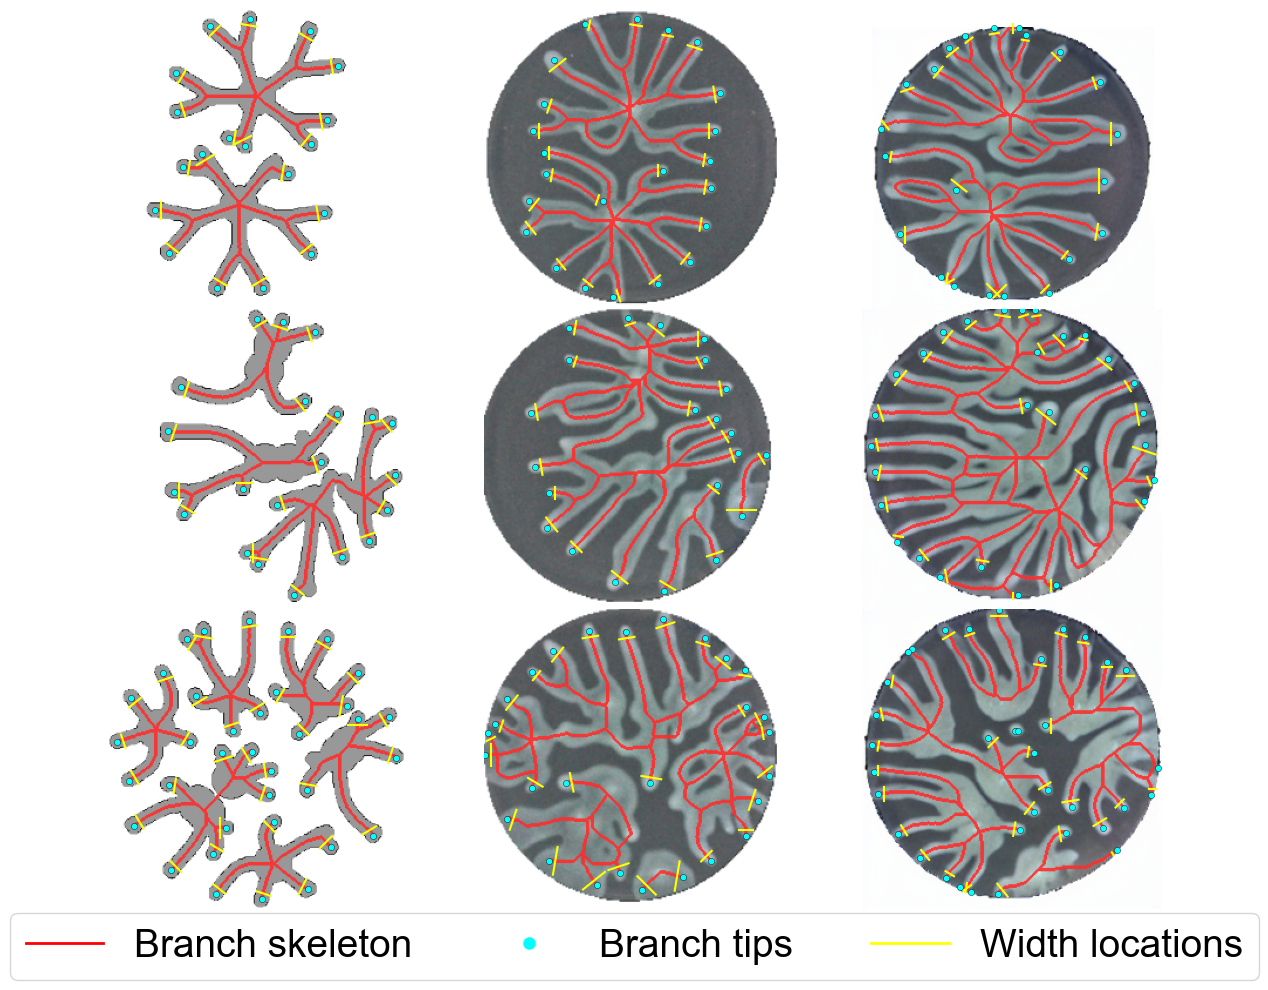

In [33]:
from cldm.preprocess import (
    preprocess_experimental_backgroundwhite,
    preprocess_simulation_graybackground,
)
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

fixed_comparison_stems = ['196_1', '241_1', '244_1']

# Rows are image stems. Columns, from left to right, are simulation,
# experiment, and diffusion. Red shows the final skeleton, cyan shows
# branch tips, and yellow shows the 5-pixel-inset width locations.
# The axes themselves contain no text, titles, or legends.
fig, axes = plt.subplots(3, 3, figsize=(11, 9), squeeze=False)

# Also adding legend at bottom 
# with extra padding so it does not overlap the images
# red skeleton
# cyan branch tips
# yellow 5-pixel-inset width locations
legend_elements = [
    Line2D([0], [0], color='red', lw=2, label='Branch skeleton'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='cyan', markersize=10, label='Branch tips'),
    Line2D([0], [0], color='yellow', lw=2, label='Width locations')
]
fig.legend(
    handles=legend_elements, loc='lower center', ncol=3,
    bbox_to_anchor=(0.5, -0.1), fontsize=COMPARISON_LEGEND_FONTSIZE,
)

for row, stem in enumerate(fixed_comparison_stems):
    simulation_image = preprocess_simulation_graybackground(
        os.path.join(SIM_FOLDER_TEST, stem + '.TIF')
    )
    simulation_gray = preprocess_simulation(
        os.path.join(SIM_FOLDER_TEST, stem + '.TIF')
    )
    simulation_blurred = cv2.GaussianBlur(
        simulation_gray,
        (SIMULATION_BLUR_KERNEL, SIMULATION_BLUR_KERNEL), 0,
    )
    simulation_mask = simulation_blurred > SIMULATION_THRESHOLD

    experimental_image = preprocess_experimental_backgroundwhite(
        os.path.join(EXP_FOLDER_TEST, stem + '.TIF')
    )
    experimental_mask = preprocess_experimental_backgroundblack_blackandwhite(
        os.path.join(EXP_FOLDER_TEST, stem + '.TIF')
    )

    diffusion_bgr = cv2.imread(
        os.path.join(MAIN_FOLDER, stem + '.png'), cv2.IMREAD_COLOR
    )
    if diffusion_bgr is None:
        raise FileNotFoundError(f'Missing diffusion image for {stem}')
    diffusion_image = cv2.cvtColor(diffusion_bgr, cv2.COLOR_BGR2RGB)
    diffusion_mask = preprocess_experimental_backgroundblack_blackandwhite_nocropping(
        os.path.join(MAIN_FOLDER, stem + '.png')
    )

    panels = []
    for image, mask in [
        (simulation_image, simulation_mask),
        (experimental_image, experimental_mask),
        (diffusion_image, diffusion_mask),
    ]:
        _, result, widths = image_metrics(mask)
        panels.append((image, result, widths))

    for ax, (image, result, widths) in zip(
        axes[row],
        panels,
    ):
        overlay = create_skeleton_overlay(image, result['final'])
        tip_y, tip_x = np.where(endpoint_pixel_map(result['final']))
        ax.imshow(overlay)
        ax.scatter(
            tip_x, tip_y, s=20, c='cyan',
            edgecolors='black', linewidths=0.3,
        )
        for _, width in widths.iterrows():
            ax.plot(
                [width['diameter_start_x'], width['diameter_end_x']],
                [width['diameter_start_y'], width['diameter_end_y']],
                color='yellow', linewidth=1.5,
            )
        ax.set_axis_off()

fig.subplots_adjust(left=0, right=1, bottom=0, top=1, wspace=0.10, hspace=0)
plt.show()


In [ ]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Hybrid PDF export: current Supp. Fig. 15A (editable legend)
from pathlib import Path
import runpy as _pdf_runpy
import matplotlib.pyplot as plt
PDF_PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                        if (p / 'figure_exports').is_dir())
_pdf_helpers = vars(_figure_exports)
_pdf_helpers['save_hybrid_pdf'](fig, PDF_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots' /
    'SuppFig15A_skeleton_overlays_hybrid_300dpi.pdf', rasterize_image_axes=True)


## Complete three-way dataframe

Run the complete paired dataframe cell above first. This joins simulation metrics
to those experimental and diffusion results and adds simulation-minus-experiment
differences. Each row remains one matched filename stem.


In [ ]:
three_way_comparison_df = comparison_df.join(
    simulation_df.add_prefix('simulation_'), how='inner'
)

for metric in (
    'branch_tip_count', 'total_skeleton_length_px',
    'mean_terminal_width_px', 'colony_area_px', 'colony_area_fraction',
):
    three_way_comparison_df[f'simulation_delta_{metric}'] = (
        three_way_comparison_df[f'simulation_{metric}']
        - three_way_comparison_df[f'exp_{metric}']
    )

display(three_way_comparison_df)

# Optional export when ready to plot the comparisons
SAVE_THREE_WAY_CSV = None
if SAVE_THREE_WAY_CSV is not None:
    three_way_comparison_df.to_csv(SAVE_THREE_WAY_CSV)


,exp_branch_tip_count,exp_total_skeleton_length_px,exp_valid_width_count,exp_mean_terminal_width_px,exp_sd_terminal_width_px,exp_median_terminal_width_px,exp_colony_area_px,exp_colony_area_fraction,diffusion_branch_tip_count,diffusion_total_skeleton_length_px,...,simulation_mean_terminal_width_px,simulation_sd_terminal_width_px,simulation_median_terminal_width_px,simulation_colony_area_px,simulation_colony_area_fraction,simulation_delta_branch_tip_count,simulation_delta_total_skeleton_length_px,simulation_delta_mean_terminal_width_px,simulation_delta_colony_area_px,simulation_delta_colony_area_fraction
image_id,,,,,,,,,,,,,,,,,,,,,
196_1,23,1531.989032,23,11.238195,1.944317,10.770330,17812,0.271790,23,1989.192134,...,13.294557,1.287551,12.806248,12791,0.195175,-4,-554.801082,2.056362,-5021,-0.076614
196_2,23,1530.834703,23,13.407896,2.838465,12.165525,20112,0.306885,23,1993.192134,...,13.262444,1.291945,12.806248,12791,0.195175,-4,-549.060967,-0.145452,-7321,-0.111710
197_1,28,2344.601297,28,13.874867,4.395562,13.416408,34622,0.528290,33,2287.258152,...,14.815609,2.125130,14.142136,17607,0.268661,0,-1209.484415,0.940742,-17015,-0.259628
197_2,23,2053.736290,23,13.813630,4.216976,13.416408,34375,0.524521,25,2244.802307,...,14.689379,2.162133,14.000000,17607,0.268661,5,-917.548340,0.875749,-16768,-0.255859
198_1,14,758.293506,14,13.550616,4.088738,13.395623,10196,0.155579,27,1920.878426,...,13.129890,0.671639,12.806248,7290,0.111237,-4,-199.865007,-0.420726,-2906,-0.044342
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249_2,22,1264.567676,22,12.435349,3.280287,12.324555,16015,0.244370,25,2240.128209,...,13.486462,1.159298,12.806248,14139,0.215744,-3,-253.119841,1.051113,-1876,-0.028625
250_1,33,1635.788022,33,12.591159,2.959466,12.649111,22027,0.336105,36,2661.029796,...,13.962592,1.506633,13.416408,18755,0.286179,-5,-248.350288,1.371434,-3272,-0.049927
250_2,30,1594.959595,30,13.617404,2.552815,13.416408,22305,0.340347,28,2180.412480,...,13.964777,1.485489,13.708204,18755,0.286179,-2,-208.450793,0.347372,-3550,-0.054169
